# Avance 3. Baseline

**Equipo 51** · Proyecto Integrador, Maestría en Inteligencia Artificial Aplicada (MNA)
**Proyecto:** AI Co-Pilot Video-to-SOP (patrocinador: Alignity)

## 0. Introducción

**Objetivo del avance.** Construir un modelo de referencia (*baseline*) para `has_errors`: dado un paso ejecutado en una grabación, ¿se hizo con error? El baseline sirve para tres cosas: (1) saber si el problema es viable con métodos simples, (2) fijar las medidas de calidad con las que se evaluarán los modelos de los avances 4 y 5 (objetivo 3.1) y (3) dejar un punto de comparación contra el que cualquier modelo más complejo tenga que justificar su costo (objetivo 3.2).

**Vínculo con el producto.** El copiloto marca, para revisión humana, los pasos sospechosos de un video antes de convertirlo en SOP o de validarlo contra uno existente. Un falso negativo (un paso con error que no se marca) termina en un procedimiento incorrecto; un falso positivo solo le cuesta al experto unos segundos de revisión. Esa asimetría guía la elección de la métrica (sección 3) y del desempeño mínimo (sección 4).

**Preguntas guía y dónde se responden**

| Pregunta | Sección |
|---|---|
| ¿Cuál es la métrica adecuada para este problema de negocio? | 3 |
| ¿Cuál debería ser el desempeño mínimo a obtener? | 4 y 8.3 |
| ¿Qué algoritmo se puede utilizar como baseline? | 5 |
| ¿Se puede determinar la importancia de las características? | 6 |
| ¿El modelo está sub/sobreajustando? | 7 |

**Particiones.** Se usa la partición oficial de CaptainCook4D por grabación, igual que en los avances 1 y 2. **Entrenamiento** se usa para ajustar, elegir el umbral y hacer validación cruzada agrupada (`GroupKFold` por grabación, 5 pliegues). **Validación** hace de conjunto no visto en este avance. **Prueba** no se toca: queda reservada para evaluar el modelo final del avance 5 (objetivo 3.6).

**Metodología.** CRISP-ML(Q), fase de *Modeling* (Studer et al., 2021): además del desempeño, se consideran las medidas "blandas" (explicabilidad, robustez, demanda de recursos, complejidad).

> **Nota de ejecución:** la libreta se corre de principio a fin (*Kernel → Restart & Run All*) en menos de un minuto. Requiere el paquete del proyecto instalado (`pip install -e ".[dev]"` desde la raíz del repositorio) y conexión a internet la primera vez para descargar ~5 MB de anotaciones.

## 1. Configuración del entorno

Las características se importan de `sopvid.features` (las mismas funciones del avance 2, sin cambios). Este avance solo agrega el modelado.

In [1]:
import time
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.feature_selection import RFECV
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupKFold, cross_val_predict, learning_curve, validation_curve

import sopvid
from sopvid.features import data
from sopvid.features import engineering as fe
from sopvid.features import preprocessing as pp

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = fe.SEED  # 51, igual que en los avances 1 y 2
np.random.seed(SEED)
CV = GroupKFold(n_splits=5)  # pliegues por grabación, como en el avance 2

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print("sopvid", sopvid.__version__, "| pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", sns.__version__)

sopvid 0.1.0 | pandas 3.0.6 | numpy 2.4.6 | sklearn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Datos: la matriz del avance 2

`fe.build_features` reproduce las decisiones del avance 2 (transformaciones, `StandardScaler`, codificación por frecuencia y selección de 35 columnas) y ajusta todo el pipeline **solo con entrenamiento**. También se construye la versión con las 46 columnas sin seleccionar, para revisar en la sección 6 las dos decisiones que quedaron abiertas (`rec_duration` y `duration`).

In [2]:
raw = data.load_raw()
steps = data.build_step_table(raw.complete, raw.errors_raw)
parts = pp.split_steps(steps, raw.splits)
graphs = data.load_task_graphs(steps["activity_name"].unique())

# Características del avance 2: el pipeline se ajusta SOLO con entrenamiento y transforma validación.
fs = fe.build_features(parts["train"], parts["val"], video_info=raw.video_info, task_graphs=graphs)
X_tr, X_va, y_tr, y_va = fs.X_train, fs.X_test, fs.y_train, fs.y_test
g_tr = parts["train"].loc[X_tr.index, "recording_id"]  # grupos para GroupKFold

# Variante con las 46 columnas (sin selección), para las comparaciones de la sección 6.
fs_all = fe.build_features(parts["train"], parts["val"], video_info=raw.video_info,
                           task_graphs=graphs, select=False)

PREV_TR, PREV_VA = y_tr.mean(), y_va.mean()
pd.DataFrame({
    "grabaciones": [g_tr.nunique(), parts["val"].loc[X_va.index, "recording_id"].nunique()],
    "pasos ejecutados": [len(X_tr), len(X_va)],
    "columnas": [X_tr.shape[1], X_va.shape[1]],
    "% con error": [100 * PREV_TR, 100 * PREV_VA],
    "faltantes": [int(X_tr.isna().sum().sum()), int(X_va.isna().sum().sum())],
}, index=["entrenamiento", "validación"])

,grabaciones,pasos ejecutados,columnas,% con error,faltantes
entrenamiento,213,2987,35,24.908,0
validación,62,884,35,37.783,0


**Observación.** La matriz no tiene faltantes. La proporción de pasos con error **no es la misma** en las particiones: 24.9 % en entrenamiento y 37.8 % en validación. La partición oficial es por grabación y a una parte de los participantes se les pidió cometer errores, así que basta con que caigan más grabaciones "con errores" en validación para mover la prevalencia. Por eso, cuando se comparen entrenamiento y validación, se reporta también el **lift** (métrica / prevalencia), que no depende de cuántos errores haya.

## 3. Métrica

### 3.1 Qué necesita el negocio

El modelo no toma decisiones por sí solo: **ordena** los pasos de un video por riesgo y marca los más sospechosos para que el experto los revise. De ahí salen tres requisitos:

1. **Clases desbalanceadas.** Solo 1 de cada 4 pasos tiene error. La exactitud premia al modelo que nunca marca nada (celda siguiente).
2. **Importa más no dejar pasar errores (recall)** que evitar revisiones de más (precisión), pero la precisión no puede caer al nivel del azar, porque entonces marcar no ahorra trabajo.
3. **El umbral todavía no está fijo.** El semáforo del producto (verde/amarillo/rojo) usará varios cortes, así que la métrica principal no debe depender de uno solo.

### 3.2 Métricas elegidas

| Rol | Métrica | Por qué |
|---|---|---|
| **Principal** | **AUC-PR** (*average precision*) | Resume toda la curva precisión-recall sin fijar un umbral. Se concentra en la clase minoritaria, a diferencia de la ROC-AUC, que con desbalance se ve optimista porque los verdaderos negativos son muchos. Su valor de referencia es la prevalencia (0.249), lo que la hace fácil de interpretar como *lift*. Es la misma métrica del avance 2. |
| Secundaria | **F2** al umbral de operación | Media armónica de precisión y recall que pesa el recall cuatro veces más (β = 2), en línea con el costo asimétrico. |
| Secundaria | **Recall y precisión** | Lo que el experto entiende: "de cada 10 errores, cuántos marcamos" y "de cada 10 marcas, cuántas eran error". |
| Diagnóstico | ROC-AUC, Brier | Comparabilidad con la literatura y calidad de las probabilidades (el semáforo las usará como puntaje). |

**Umbral de operación.** Se elige el que maximiza F2 sobre las predicciones **fuera de pliegue de entrenamiento** y se aplica sin cambios a validación.

In [3]:
def scores(y, p, thr):
    """Métricas de la sección 3: AUC-PR (principal) y las secundarias al umbral de operación."""
    yhat = (p >= thr).astype(int)
    return {
        "AUC-PR": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "F2": fbeta_score(y, yhat, beta=2, zero_division=0),
        "Recall": recall_score(y, yhat, zero_division=0),
        "Precisión": precision_score(y, yhat, zero_division=0),
        "% marcados": 100 * yhat.mean(),
        "Brier": brier_score_loss(y, p),
    }


def oof_proba(model, X, y, groups=g_tr):
    """Probabilidades fuera de pliegue (cada paso se predice con un modelo que no vio su grabación)."""
    return cross_val_predict(clone(model), X, y, groups=groups, cv=CV, method="predict_proba")[:, 1]


def cv_ap(model, X, y, groups=g_tr):
    """AUC-PR por pliegue (media y desviación), igual que en el avance 2."""
    out = []
    for tr, te in CV.split(X, y, groups):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        out.append(average_precision_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1]))
    return np.array(out)


def f2_threshold(y, p):
    """Umbral que maximiza F2 sobre probabilidades fuera de pliegue de ENTRENAMIENTO."""
    prec, rec, thr = precision_recall_curve(y, p)
    f2 = 5 * prec * rec / np.clip(4 * prec + rec, 1e-12, None)
    return float(thr[np.argmax(f2[:-1])])

In [4]:
# ¿Por qué no exactitud? Un clasificador que nunca marca error ya es "bueno" en exactitud.
always_ok = np.zeros_like(y_tr)
print(f"Exactitud de 'nunca hay error' en entrenamiento: {(always_ok == y_tr).mean():.1%}")
print(f"Recall de 'nunca hay error': {recall_score(y_tr, always_ok):.1%}")
print(f"AUC-PR de un clasificador al azar = prevalencia = {PREV_TR:.3f} (entrenamiento) "
      f"y {PREV_VA:.3f} (validación)")

Exactitud de 'nunca hay error' en entrenamiento: 75.1%
Recall de 'nunca hay error': 0.0%
AUC-PR de un clasificador al azar = prevalencia = 0.249 (entrenamiento) y 0.378 (validación)


**Interpretación.** Un modelo que siempre dice "sin error" tiene 75.1 % de exactitud y recall 0: la exactitud no sirve aquí. En cambio, el AUC-PR de un clasificador al azar es exactamente la prevalencia, así que cualquier valor por encima de 0.249 (entrenamiento) o 0.378 (validación) es señal real.

## 4. Desempeño mínimo

**No existe un desempeño histórico.** El cliente revisa sus videos a mano y no hay un sistema previo que detecte pasos con error, ni con CaptainCook4D ni en planta. Por eso el mínimo se construye con dos tipos de referencia, fijadas **antes** de entrenar el baseline:

1. **Soluciones triviales** que cualquiera podría implementar sin aprendizaje automático: el azar y reglas de una sola variable tomadas del EDA (avances 1 y 2): marcar los pasos fuera de orden, los que duran menos que lo típico de su paso o los de videos más cortos.
2. **Un criterio de negocio:** marcar debe ahorrarle trabajo al experto.

| Criterio | Condición | Justificación |
|---|---|---|
| **M1** | AUC-PR ≥ 1.5 × prevalencia | Las marcas deben tener al menos 50 % más errores que una muestra al azar. |
| **M2** | AUC-PR > mejor regla simple | Si una regla de una línea iguala al modelo, el modelo no se justifica. |
| **M3** | Recall ≥ 70 % con precisión ≥ 1.4 × prevalencia | Con la prevalencia de entrenamiento equivale a **encontrar 7 de cada 10 errores revisando como mucho la mitad de los pasos** (0.70 × 0.249 / 0.50 ≈ 0.35 ≈ 1.4 × 0.249). Se expresa como *lift* para poder aplicarlo igual en validación, que tiene otra prevalencia. |

In [5]:
# Criterios fijados ANTES de entrenar el baseline (sección 4).
MIN_LIFT = 1.5        # M1: AUC-PR >= 1.5 x prevalencia
MIN_RECALL = 0.70     # M3: detectar al menos 70 % de los pasos con error...
MIN_PREC_LIFT = 1.4   # ...con precisión >= 1.4 x prevalencia (en train equivale a marcar <= 50 % de los pasos)

# Referencias sin aprendizaje (o con una sola variable): la "solución trivial" a superar.
# Las columnas están estandarizadas, pero el orden de los valores (lo único que usa el AUC-PR) se conserva.
rules = {
    "Azar (prevalencia)": lambda X: np.full(len(X), 0.5),
    "Regla de orden: order_violation = 1": lambda X: X["order_violation"].to_numpy(),
    "Regla de duración: paso más corto que su típico": lambda X: -X["dur_ratio_step"].to_numpy(),
    "Regla de grabación: video más corto": lambda X: -X["rec_duration"].to_numpy(),
}
ref = []
for name, f in rules.items():
    ref.append({"referencia": name,
                "AUC-PR train": average_precision_score(y_tr, f(X_tr)),
                "AUC-PR val": average_precision_score(y_va, f(X_va))})
ref = pd.DataFrame(ref).set_index("referencia")
ref["lift train"] = ref["AUC-PR train"] / PREV_TR
ref["lift val"] = ref["AUC-PR val"] / PREV_VA
BEST_RULE = ref.drop(index="Azar (prevalencia)")["AUC-PR train"].idxmax()
print("Mínimo M1 (AUC-PR):", f"{MIN_LIFT * PREV_TR:.3f} en entrenamiento / {MIN_LIFT * PREV_VA:.3f} en validación")
print("Mejor regla simple (M2):", BEST_RULE)
ref.sort_values("AUC-PR train", ascending=False)

Mínimo M1 (AUC-PR): 0.374 en entrenamiento / 0.567 en validación
Mejor regla simple (M2): Regla de grabación: video más corto


,AUC-PR train,AUC-PR val,lift train,lift val
referencia,,,,
Regla de grabación: video más corto,0.401,0.503,1.609,1.332
Regla de duración: paso más corto que su típico,0.339,0.461,1.362,1.221
Regla de orden: order_violation = 1,0.289,0.472,1.159,1.249
Azar (prevalencia),0.249,0.378,1.000,1.000


In [6]:
# La regla de orden es muy precisa pero cubre muy pocos pasos.
ov_tr, ov_va = X_tr["order_violation"] > 0, X_va["order_violation"] > 0
pd.DataFrame({
    "pasos marcados": [ov_tr.sum(), ov_va.sum()],
    "% marcados": [100 * ov_tr.mean(), 100 * ov_va.mean()],
    "precisión": [y_tr[ov_tr].mean(), y_va[ov_va].mean()],
    "recall": [y_tr[ov_tr].sum() / y_tr.sum(), y_va[ov_va].sum() / y_va.sum()],
}, index=["entrenamiento", "validación"])

,pasos marcados,% marcados,precisión,recall
entrenamiento,88,2.946,0.716,0.085
validación,63,7.127,0.921,0.174


**Interpretación.** La mejor regla simple es "marcar los pasos de los videos más cortos" (AUC-PR 0.401, lift 1.61): confirma lo visto en el avance 2, donde `rec_duration` concentraba la señal. Es una regla **de grabación**, no de paso: marca todos los pasos de un video por igual. La regla de duración relativa (0.339) y la de orden (0.289) quedan por encima del azar, pero lejos. La regla de orden es muy precisa (72 % en entrenamiento y 92 % en validación), pero solo cubre 3 % a 7 % de los pasos, así que su recall es de 9 % a 17 %: útil como alerta de alta confianza, insuficiente como detector.

El baseline tiene que superar **0.401** (M2) y **0.374** (M1) en entrenamiento.

## 5. Algoritmo del baseline: regresión logística

### 5.1 Por qué regresión logística

| Aspecto | Situación de los datos | Consecuencia |
|---|---|---|
| Tipo de problema | Clasificación binaria | Se necesita un clasificador que produzca **probabilidades** (el semáforo del producto las convierte en niveles). La regresión logística las estima directamente. |
| Tipo de datos | **Estructurados** (tabla de 35 columnas numéricas y binarias), no imágenes ni texto | No hace falta un modelo de representación; un modelo lineal sobre las características es el punto de partida estándar. |
| Cantidad de datos | 2,987 pasos de **solo 213 grabaciones** | Pocos grupos independientes: un modelo con muchos grados de libertad se sobreajustaría a las grabaciones. Con 35 coeficientes y regularización L2 el riesgo es bajo. |
| Preparación previa | Asimetrías corregidas (Yeo-Johnson, log1p), todo estandarizado, sin faltantes, sin colinealidad fuerte (ρ < 0.9) | Es justo lo que necesita un modelo lineal; las decisiones del avance 2 se tomaron con este modelo. |
| Desbalance | 24.9 % de positivos | `class_weight="balanced"` pondera más la clase minoritaria sin crear datos sintéticos. |
| Explicabilidad | Cada advertencia del copiloto debe poder explicarse | Los coeficientes estandarizados y las razones de momios dicen **qué** aumenta el riesgo y **cuánto**. |
| Recursos | Producto local y de costo cero | Entrena en milisegundos en CPU y predice con un producto punto. |

Siguiendo CRISP-ML(Q), el baseline es el modelo **más simple que cumple las restricciones**: máxima explicabilidad, mínima demanda de recursos y mínima complejidad. Los modelos no lineales y los ensambles (árboles potenciados, bosques, etc.) se exploran en los avances 4 y 5 y tendrán que superar a este baseline para justificar su complejidad.

**Hiperparámetros.** `C = 1` (valor por defecto de scikit-learn, regularización L2 moderada) y `max_iter = 5000`. En la sección 7.3 se verifica con una curva de validación que no hace falta ajustar `C`.

In [7]:
baseline = LogisticRegression(class_weight="balanced", max_iter=5000)  # C = 1 (sección 7.3)

t0 = time.perf_counter()
baseline.fit(X_tr, y_tr)
fit_time = time.perf_counter() - t0

p_oof = oof_proba(baseline, X_tr, y_tr)        # entrenamiento, fuera de pliegue
p_in = baseline.predict_proba(X_tr)[:, 1]      # entrenamiento, dentro de muestra
p_va = baseline.predict_proba(X_va)[:, 1]      # validación (no vista)
ap_folds = cv_ap(baseline, X_tr, y_tr)

THR = f2_threshold(y_tr, p_oof)                # umbral elegido SOLO con entrenamiento
print(f"Tiempo de entrenamiento: {fit_time * 1000:.0f} ms | coeficientes: {baseline.coef_.size}")
print(f"AUC-PR por pliegue: {np.round(ap_folds, 3)} -> {ap_folds.mean():.3f} ± {ap_folds.std():.3f}")
print(f"Umbral de operación (máx. F2 fuera de pliegue): {THR:.3f}")

Tiempo de entrenamiento: 16 ms | coeficientes: 35
AUC-PR por pliegue: [0.612 0.578 0.52  0.494 0.55 ] -> 0.551 ± 0.042
Umbral de operación (máx. F2 fuera de pliegue): 0.308


**Interpretación.** El modelo entrena en unos 15 ms. La media por pliegue del AUC-PR (0.551 ± 0.042) coincide con la del avance 2 para las 35 columnas seleccionadas (0.553). Los pliegues van de 0.494 a 0.612: hay variación entre grupos de grabaciones, algo esperable con solo ~43 grabaciones por pliegue. El umbral que maximiza F2 es 0.31, bajo, como corresponde a una métrica que privilegia el recall.

Como contraste se entrena un árbol de decisión de profundidad 3, igual de simple y explicable, pero no lineal:

In [8]:
# Contraste rápido: ¿un modelo igual de simple pero no lineal cambia el panorama?
from sklearn.tree import DecisionTreeClassifier

contrast = {
    "Regresión logística (baseline)": baseline,
    "Árbol de decisión, profundidad 3": DecisionTreeClassifier(max_depth=3, class_weight="balanced",
                                                                 random_state=SEED),
}
rows = []
for name, m in contrast.items():
    t0 = time.perf_counter(); m_fit = clone(m).fit(X_tr, y_tr); t = time.perf_counter() - t0
    f = cv_ap(m, X_tr, y_tr)
    rows.append({"modelo": name, "AUC-PR CV": f.mean(), "desv.": f.std(),
                 "AUC-PR val": average_precision_score(y_va, m_fit.predict_proba(X_va)[:, 1]),
                 "entrenamiento (ms)": 1000 * t})
pd.DataFrame(rows).set_index("modelo")

,AUC-PR CV,desv.,AUC-PR val,entrenamiento (ms)
modelo,,,,
Regresión logística (baseline),0.551,0.042,0.680,16.295
"Árbol de decisión, profundidad 3",0.337,0.040,0.561,5.555


**Interpretación.** El árbol poco profundo apenas supera a la regla de grabación (0.337 contra 0.551 de la regresión logística en CV). Con tres cortes no puede combinar las señales débiles que la regresión logística suma (posición, orden, receta, duración de la grabación). Esto respalda la elección de la regresión logística como baseline: no es solo la más simple, también es la más fuerte entre las alternativas igual de explicables.

## 6. Importancia de las características

Se usan tres familias de métodos, porque cada una responde una pregunta diferente:

| Método | Tipo | Pregunta |
|---|---|---|
| Coeficientes estandarizados | Embebido | ¿Hacia dónde y con qué fuerza empuja cada variable el riesgo, con las demás fijas? |
| Trayectoria L1 (lasso) | Embebido | ¿Qué variables sobreviven cuando se obliga al modelo a ser escaso? |
| Importancia por permutación | Agnóstico | ¿Cuánto AUC-PR se pierde **en datos no vistos** si una variable se vuelve ruido? |
| RFECV | Envoltura | ¿Cuántas columnas hacen falta realmente? |

### 6.1 Coeficientes (embebido)

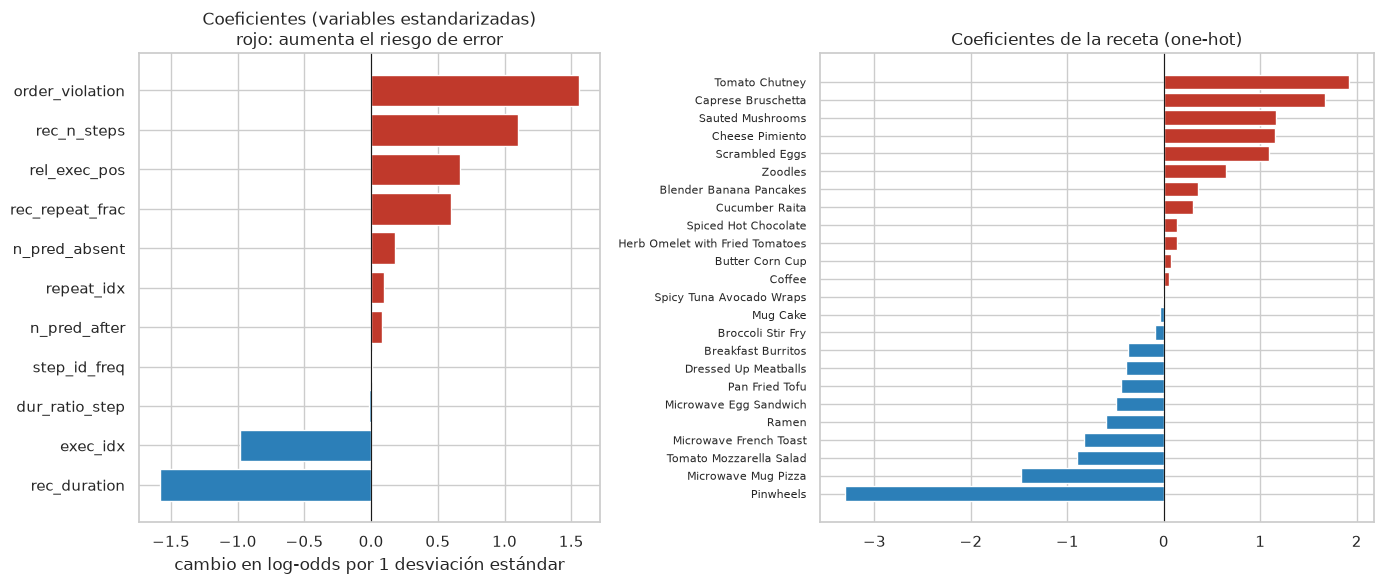

,razón de momios,coeficiente
rec_duration,0.205,-1.586
order_violation,4.761,1.560
rec_n_steps,3.012,1.103
exec_idx,0.374,-0.982
rel_exec_pos,1.947,0.666
rec_repeat_frac,1.813,0.595
n_pred_absent,1.199,0.182
repeat_idx,1.098,0.093
n_pred_after,1.084,0.081
dur_ratio_step,0.984,-0.017


In [9]:
coef = pd.Series(baseline.coef_[0], index=X_tr.columns)
is_recipe = coef.index.str.startswith("activity_name_")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.2]})
c1 = coef[~is_recipe].sort_values()
axes[0].barh(c1.index, c1.values, color=np.where(c1 > 0, "#c0392b", "#2c7fb8"))
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("Coeficientes (variables estandarizadas)\nrojo: aumenta el riesgo de error")
axes[0].set_xlabel("cambio en log-odds por 1 desviación estándar")

c2 = coef[is_recipe].sort_values()
c2.index = c2.index.str.replace("activity_name_", "")
axes[1].barh(c2.index, c2.values, color=np.where(c2 > 0, "#c0392b", "#2c7fb8"))
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_title("Coeficientes de la receta (one-hot)")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

odds = np.exp(coef[~is_recipe]).rename("razón de momios").to_frame()
odds["coeficiente"] = coef[~is_recipe]
odds.sort_values("coeficiente", key=abs, ascending=False)

**Interpretación.** Como todas las variables están estandarizadas, los coeficientes son comparables (cambio en log-odds por una desviación estándar):

- **`rec_duration` (−1.59, razón de momios 0.21):** cada desviación estándar más de duración del video divide entre ~5 los momios de error. Es el patrón del dataset: las grabaciones con errores son más cortas.
- **`order_violation` (+1.56, ×4.8):** hacer un paso antes que su predecesor en la receta casi quintuplica los momios. Es la señal **de paso** más fuerte y la más transferible a planta: en un SOP real también existe un orden esperado.
- **`rec_n_steps` (+1.10)** y **`exec_idx` (−0.98):** a igual duración, las grabaciones con más pasos tienen más error, y dentro del video los errores aparecen antes (como en el avance 2: mediana de `exec_idx` 5 contra 7).
- **`dur_ratio_step` y `step_id_freq` quedan casi en 0.** La duración relativa sí se asociaba con el error en el avance 2, pero, con las variables de grabación presentes, sola ya no aporta. La sección 6.5 muestra que vuelve a servir cuando se agrega `duration`.
- **Recetas:** funcionan como un nivel base de riesgo por receta, de *Pinwheels* (−3.3) y *Microwave Mug Pizza* (−1.5) a *Tomato Chutney* (+1.9) y *Caprese Bruschetta* (+1.7). En planta, el equivalente sería un nivel base por SOP o por línea de producción.

### 6.2 Trayectoria L1 (embebido)

Con penalización L1, al aumentar la regularización (C menor) los coeficientes van llegando a 0. El orden en que una variable **entra** al modelo indica qué tan indispensable es.

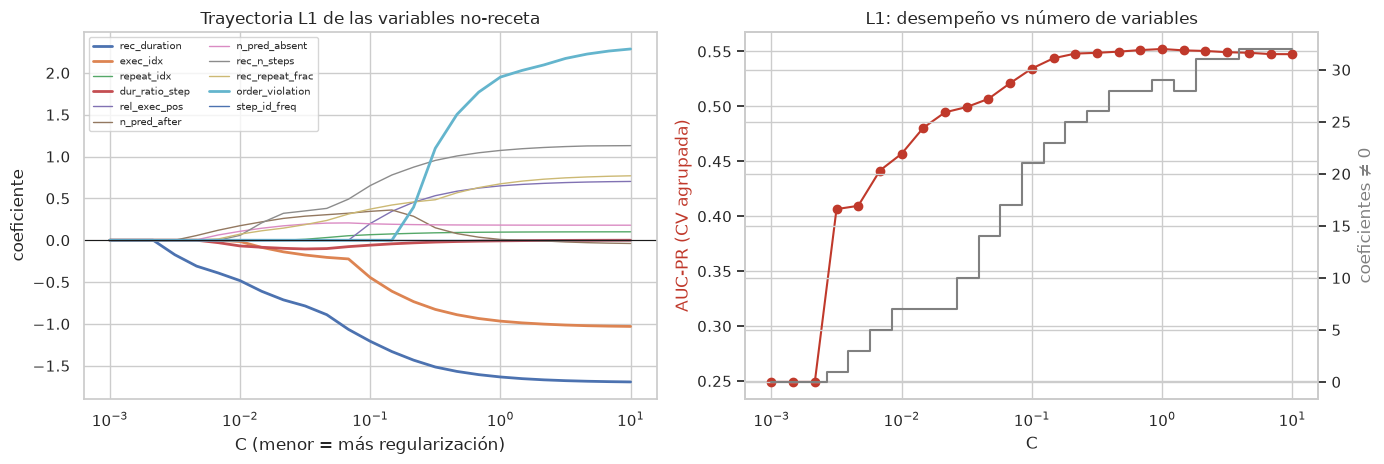

Mejor L1: C = 1.000, AUC-PR CV = 0.552, coeficientes ≠ 0 = 29


,C de entrada
rec_duration,0.003
n_pred_after,0.005
n_pred_absent,0.005
dur_ratio_step,0.007
rec_repeat_frac,0.007
rec_n_steps,0.010
exec_idx,0.010
repeat_idx,0.032
rel_exec_pos,0.100
order_violation,0.215


In [10]:
# Método embebido: regularización L1 (lasso). Al bajar C, los coeficientes poco útiles llegan a 0.
Cs = np.logspace(-3, 1, 25)
num_cols = list(X_tr.columns[~is_recipe])
paths, ap_l1, nnz = [], [], []
for C in Cs:
    m = LogisticRegression(l1_ratio=1.0, solver="liblinear", C=C, class_weight="balanced", max_iter=5000)
    m.fit(X_tr, y_tr)
    paths.append(pd.Series(m.coef_[0], index=X_tr.columns))
    nnz.append(int((m.coef_[0] != 0).sum()))
    ap_l1.append(cv_ap(m, X_tr, y_tr).mean())
paths = pd.DataFrame(paths, index=Cs)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for c in num_cols:
    axes[0].plot(Cs, paths[c], label=c, lw=2 if c in ("rec_duration", "dur_ratio_step",
                                                     "order_violation", "exec_idx") else 1)
axes[0].set_xscale("log"); axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xlabel("C (menor = más regularización)"); axes[0].set_ylabel("coeficiente")
axes[0].set_title("Trayectoria L1 de las variables no-receta")
axes[0].legend(fontsize=7, ncol=2)
ax2 = axes[1]; ax2.plot(Cs, ap_l1, "o-", color="#c0392b"); ax2.set_xscale("log")
ax2.set_xlabel("C"); ax2.set_ylabel("AUC-PR (CV agrupada)", color="#c0392b")
ax3 = ax2.twinx(); ax3.step(Cs, nnz, where="mid", color="gray"); ax3.set_ylabel("coeficientes ≠ 0", color="gray")
ax2.set_title("L1: desempeño vs número de variables")
plt.tight_layout(); plt.show()

# Orden de entrada: la primera C en la que cada variable no-receta deja de ser 0
entry = {c: Cs[np.argmax(paths[c].to_numpy() != 0)] if (paths[c] != 0).any() else np.nan for c in num_cols}
best_i = int(np.argmax(ap_l1))
print(f"Mejor L1: C = {Cs[best_i]:.3f}, AUC-PR CV = {ap_l1[best_i]:.3f}, coeficientes ≠ 0 = {nnz[best_i]}")
pd.Series(entry, name="C de entrada").sort_values().to_frame()

**Interpretación.** `rec_duration` es la primera variable que entra (C ≈ 0.003): con regularización fuerte, el modelo se queda con ella y casi nada más. Le siguen el orden de la receta (`n_pred_after`, `n_pred_absent`), `dur_ratio_step` y las demás de grabación. `step_id_freq` **nunca** entra en el rango probado: no aporta. El mejor AUC-PR con L1 (0.552 en C = 1, con 29 coeficientes distintos de 0) es igual al del baseline con L2 (0.551): la escasez no mejora el desempeño, así que se mantiene L2. L1 confirma que unas 6 columnas no son necesarias.

### 6.3 Importancia por permutación en validación

Se desordena una variable en validación (30 repeticiones) y se mide cuánto cae el AUC-PR. Las 24 columnas de receta se permutan juntas, porque representan una sola variable.

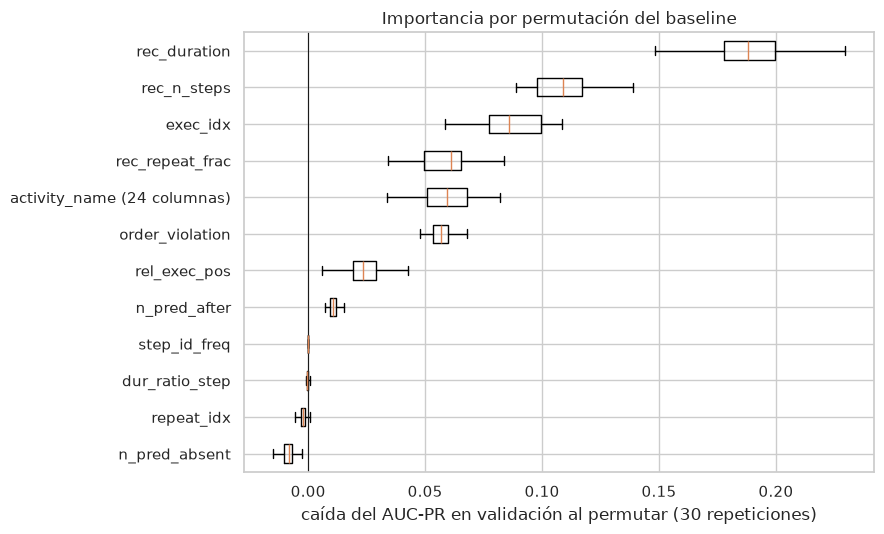

,mean,std
rec_duration,0.188,0.016
rec_n_steps,0.108,0.013
exec_idx,0.087,0.014
rec_repeat_frac,0.060,0.014
activity_name (24 columnas),0.059,0.012
order_violation,0.058,0.006
rel_exec_pos,0.024,0.009
n_pred_after,0.011,0.002
step_id_freq,0.000,0.000
dur_ratio_step,-0.000,0.000


In [11]:
# Importancia por permutación en VALIDACIÓN (caída del AUC-PR al desordenar una variable).
# Las 24 columnas de receta se permutan juntas, como una sola variable.
rng = np.random.default_rng(SEED)
blocks = {c: [c] for c in num_cols}
blocks["activity_name (24 columnas)"] = list(X_tr.columns[is_recipe])
base_ap = average_precision_score(y_va, p_va)
N_REP = 30
imp = {}
for name, cols in blocks.items():
    drops = []
    for _ in range(N_REP):
        Xp = X_va.copy()
        perm = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].to_numpy()[perm]
        drops.append(base_ap - average_precision_score(y_va, baseline.predict_proba(Xp)[:, 1]))
    imp[name] = drops
imp = pd.DataFrame(imp)
order = imp.mean().sort_values().index

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.boxplot([imp[c] for c in order], orientation="horizontal", tick_labels=order, showfliers=False)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("caída del AUC-PR en validación al permutar (30 repeticiones)")
ax.set_title("Importancia por permutación del baseline")
plt.tight_layout(); plt.show()
imp.agg(["mean", "std"]).T.sort_values("mean", ascending=False)

**Interpretación.** En datos no vistos, el ranking es claro:

1. **`rec_duration`** es por mucho la más importante (−0.188 de AUC-PR al permutarla, de 0.680 a ~0.49).
2. Le siguen `rec_n_steps` (−0.108), `exec_idx` (−0.087), `rec_repeat_frac` (−0.060), la receta (−0.059) y `order_violation` (−0.058).
3. `dur_ratio_step`, `step_id_freq`, `repeat_idx` y `n_pred_absent` no aportan nada en validación (caídas de 0 o negativas, dentro del ruido).

Tres de las cuatro más importantes son **de grabación** (`rec_*`): el modelo distingue sobre todo *qué videos* tienen errores, más que *qué pasos* dentro de un video. Esto refuerza el riesgo señalado en el avance 2: esa señal depende de cómo se construyó CaptainCook4D (a algunos participantes se les pidió equivocarse) y no necesariamente se transferirá a la planta.

### 6.4 Eliminación recursiva con validación cruzada (envoltura)

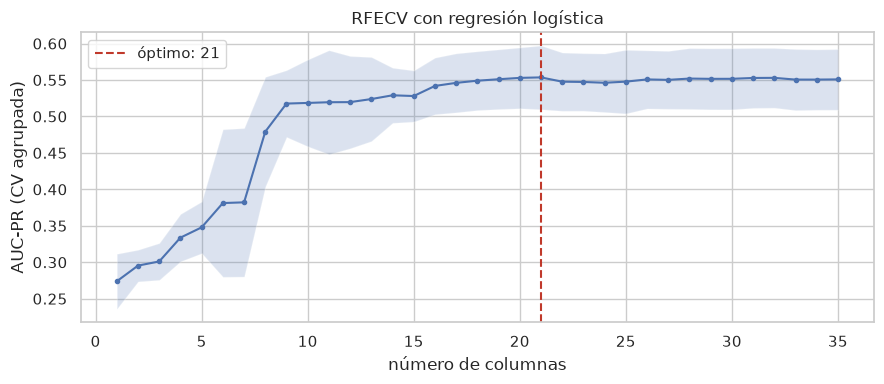

RFECV (2.1 s): 21 columnas, AUC-PR CV = 0.554
Descartadas: ['repeat_idx', 'dur_ratio_step', 'n_pred_after', 'n_pred_absent', 'activity_name_Blender Banana Pancakes', 'activity_name_Broccoli Stir Fry', 'activity_name_Butter Corn Cup', 'activity_name_Coffee', 'activity_name_Cucumber Raita', 'activity_name_Herb Omelet with Fried Tomatoes', 'activity_name_Mug Cake', 'activity_name_Spiced Hot Chocolate', 'activity_name_Spicy Tuna Avocado Wraps', 'step_id_freq']


In [12]:
# Método de envoltura: eliminación recursiva con validación cruzada agrupada (RFECV).
t0 = time.perf_counter()
rfe = RFECV(LogisticRegression(class_weight="balanced", max_iter=5000), step=1, cv=CV,
            scoring="average_precision", min_features_to_select=1)
rfe.fit(X_tr, y_tr, groups=g_tr)
res = pd.DataFrame({k: rfe.cv_results_[k] for k in ("n_features", "mean_test_score", "std_test_score")})

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(res["n_features"], res["mean_test_score"], "o-", ms=3)
ax.fill_between(res["n_features"], res["mean_test_score"] - res["std_test_score"],
                res["mean_test_score"] + res["std_test_score"], alpha=0.2)
ax.axvline(rfe.n_features_, color="#c0392b", ls="--", label=f"óptimo: {rfe.n_features_}")
ax.set_xlabel("número de columnas"); ax.set_ylabel("AUC-PR (CV agrupada)")
ax.set_title("RFECV con regresión logística"); ax.legend()
plt.tight_layout(); plt.show()

rfe_cols = list(X_tr.columns[rfe.support_])
print(f"RFECV ({time.perf_counter() - t0:.1f} s): {rfe.n_features_} columnas, "
      f"AUC-PR CV = {res['mean_test_score'].max():.3f}")
print("Descartadas:", [c for c in X_tr.columns if c not in rfe_cols])

**Interpretación.** Con 1 a 7 columnas el AUC-PR sube de 0.27 a 0.38; con la octava y novena salta a ~0.52, y a partir de ~16 columnas la curva queda plana dentro de la banda de ±1 desviación. RFECV se queda con 21 columnas (AUC-PR 0.554) y descarta `repeat_idx`, `dur_ratio_step`, `n_pred_after`, `n_pred_absent`, `step_id_freq` y 9 columnas de receta, en línea con lo que dicen L1 y la permutación. La ganancia frente a las 35 (0.551) es mínima y la selección se hizo con todo entrenamiento, así que es algo optimista.

### 6.5 Decisiones abiertas del avance 2: `rec_duration` y `duration`

Se compara el mismo modelo con distintos conjuntos de características, con la misma validación cruzada agrupada. "Pliegues mejores que A" cuenta en cuántos de los 5 pliegues la variante supera al baseline: una mejora en 5 de 5 pliegues no es ruido aunque sea menor que la desviación.

In [13]:
# ¿Cambia el baseline con otro conjunto de características? (decisiones abiertas del avance 2)
Xa_tr, Xa_va = fs_all.X_train, fs_all.X_test
variants = {
    "A. Seleccionadas en el avance 2 (35)": (X_tr, X_va),
    "B. A sin rec_duration (34)": (X_tr.drop(columns="rec_duration"), X_va.drop(columns="rec_duration")),
    "C. A + duration (36)": (X_tr.join(Xa_tr["duration"]), X_va.join(Xa_va["duration"])),
    "D. C sin rec_duration (35)": (X_tr.join(Xa_tr["duration"]).drop(columns="rec_duration"),
                                   X_va.join(Xa_va["duration"]).drop(columns="rec_duration")),
    "E. Todas las construidas (46)": (Xa_tr, Xa_va),
    f"F. RFECV ({len(rfe_cols)})": (X_tr[rfe_cols], X_va[rfe_cols]),
}
rows, ap_fold_table = [], {}
for name, (a, b) in variants.items():
    f = cv_ap(baseline, a, y_tr)
    ap_fold_table[name] = f
    m = clone(baseline).fit(a, y_tr)
    rows.append({"variante": name, "columnas": a.shape[1], "AUC-PR CV": f.mean(), "desv.": f.std(),
                 "Δ vs A (CV)": f.mean() - ap_folds.mean(),
                 "pliegues mejores que A": int((f > ap_folds + 1e-9).sum()),
                 "AUC-PR val": average_precision_score(y_va, m.predict_proba(b)[:, 1])})
var_tab = pd.DataFrame(rows).set_index("variante")
var_tab

,columnas,AUC-PR CV,desv.,Δ vs A (CV),pliegues mejores que A,AUC-PR val
variante,,,,,,
A. Seleccionadas en el avance 2 (35),35,0.551,0.042,0.000,0,0.680
B. A sin rec_duration (34),34,0.474,0.022,-0.077,0,0.628
C. A + duration (36),36,0.568,0.045,0.017,5,0.690
D. C sin rec_duration (35),35,0.481,0.021,-0.070,0,0.638
E. Todas las construidas (46),46,0.570,0.044,0.019,4,0.693
F. RFECV (21),21,0.560,0.045,0.009,3,0.685


**Interpretación y decisiones**

- **`duration` sí aporta (C: +0.017, mejor en 5 de 5 pliegues; validación 0.690 contra 0.680).** Confirma el diagnóstico del avance 2: `duration` sola no se relaciona con el error, pero junto con `dur_ratio_step` permite reconstruir la duración típica del paso (en esa variante `duration` tiene coeficiente +0.37 y `dur_ratio_step` −0.19: un paso más corto **que su típico** es más riesgoso). **Decisión:** se agrega `duration` al conjunto que recibirá el avance 4.
- **`rec_duration` es la diferencia entre un buen y un mal baseline (B: −0.077, peor en 5 de 5).** Sin ella el AUC-PR cae a 0.474 en CV y 0.628 en validación. Aun así, la variante B **sigue cumpliendo M1** (lift 1.90 en CV) y supera a todas las reglas que no usan la duración del video. **Decisión:** se reportan ambos baselines. El de 35 columnas es la referencia académica; la variante sin `rec_duration` es la referencia **transferible al producto**, porque en planta la duración del video depende de cómo se grabe y no de si hubo errores.
- **Todas las columnas (E)** igualan a C (0.570 contra 0.568): las otras 10 eliminadas en el avance 2 no aportan. **RFECV (F)** queda entre A y C con 21 columnas.
- Para no mezclar decisiones con la evaluación, el **baseline oficial de este avance sigue siendo A** (las 35 columnas de `build_features`), y las secciones 7 y 8 lo evalúan a él.

## 7. Sub y sobreajuste

### 7.1 Métricas en entrenamiento, validación cruzada y validación

- **Entrenamiento (dentro de muestra):** el modelo predice los mismos pasos con los que se ajustó.
- **CV agrupada:** cada paso se predice con un modelo que no vio su grabación. Aquí el AUC-PR se calcula sobre todas las predicciones fuera de pliegue juntas (0.514), que es más conservador que la media por pliegue (0.551) porque mezcla probabilidades de cinco modelos distintos.
- **Validación:** grabaciones nunca vistas.

In [14]:
# Mismas métricas en entrenamiento (dentro de muestra), CV (fuera de pliegue) y validación.
fit_tab = pd.DataFrame({
    "entrenamiento (dentro de muestra)": scores(y_tr, p_in, THR),
    "CV agrupada (fuera de pliegue)": scores(y_tr, p_oof, THR),
    "validación (no vista)": scores(y_va, p_va, THR),
}).T
fit_tab["prevalencia"] = [PREV_TR, PREV_TR, PREV_VA]
fit_tab["lift AUC-PR"] = fit_tab["AUC-PR"] / fit_tab["prevalencia"]
fit_tab

,AUC-PR,ROC-AUC,F2,Recall,Precisión,% marcados,Brier,prevalencia,lift AUC-PR
entrenamiento (dentro de muestra),0.588,0.823,0.733,0.931,0.396,58.621,0.173,0.249,2.359
CV agrupada (fuera de pliegue),0.514,0.772,0.701,0.882,0.385,57.114,0.192,0.249,2.063
validación (no vista),0.680,0.802,0.777,0.871,0.542,60.747,0.183,0.378,1.799


**Interpretación.**

- **Brecha pequeña entre entrenamiento y CV:** AUC-PR 0.588 contra 0.514 (−0.07), ROC-AUC 0.823 contra 0.772, F2 0.733 contra 0.701. Hay algo de optimismo dentro de muestra, pero no un sobreajuste fuerte.
- **Validación es más alta que CV en AUC-PR (0.680), pero no en lift (1.80 contra 2.06).** El AUC-PR sube porque validación tiene más errores (37.8 %), no porque el modelo funcione mejor ahí. Medido contra el azar de cada partición, el modelo rinde un poco **peor** en datos nuevos, como es lo normal. La ROC-AUC, que no depende de la prevalencia, también queda entre entrenamiento y CV (0.802).
- **Los valores absolutos son modestos en las tres columnas.** Incluso con los datos que ya vio, el modelo solo llega a AUC-PR 0.588 (ROC-AUC 0.82). Ese techo bajo en entrenamiento es la firma del **subajuste**, que se confirma con las curvas siguientes.

### 7.2 Curva de aprendizaje y curva de validación

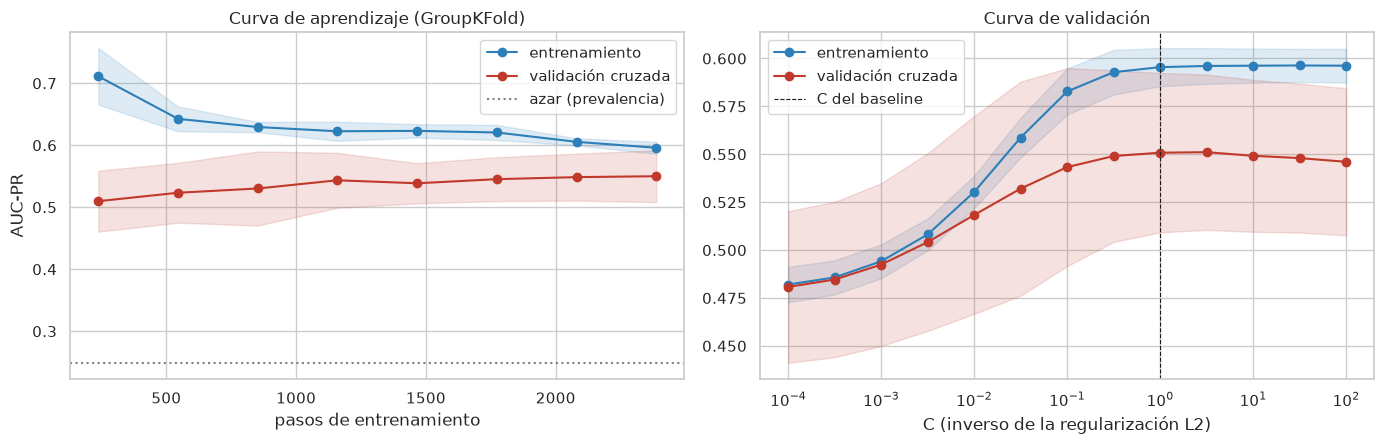

Curva de aprendizaje (media):
 pasos  train    CV  brecha
   238  0.711 0.510   0.201
   545  0.643 0.523   0.119
   852  0.629 0.530   0.099
  1159  0.623 0.544   0.079
  1466  0.623 0.539   0.085
  1773  0.621 0.545   0.075
  2080  0.606 0.549   0.057
  2387  0.596 0.550   0.046


In [15]:
sizes, tr_sc, te_sc = learning_curve(
    clone(baseline), X_tr, y_tr, groups=g_tr, cv=CV, scoring="average_precision",
    train_sizes=np.linspace(0.1, 1.0, 8), shuffle=True, random_state=SEED)
Cs_v = np.logspace(-4, 2, 13)
v_tr, v_te = validation_curve(clone(baseline), X_tr, y_tr, groups=g_tr, cv=CV,
                              param_name="C", param_range=Cs_v, scoring="average_precision")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for sc, lab, col in [(tr_sc, "entrenamiento", "#2c7fb8"), (te_sc, "validación cruzada", "#c0392b")]:
    axes[0].plot(sizes, sc.mean(1), "o-", color=col, label=lab)
    axes[0].fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=col, alpha=0.15)
axes[0].axhline(PREV_TR, color="gray", ls=":", label="azar (prevalencia)")
axes[0].set_xlabel("pasos de entrenamiento"); axes[0].set_ylabel("AUC-PR")
axes[0].set_title("Curva de aprendizaje (GroupKFold)"); axes[0].legend()

for sc, lab, col in [(v_tr, "entrenamiento", "#2c7fb8"), (v_te, "validación cruzada", "#c0392b")]:
    axes[1].plot(Cs_v, sc.mean(1), "o-", color=col, label=lab)
    axes[1].fill_between(Cs_v, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=col, alpha=0.15)
axes[1].axvline(1.0, color="k", ls="--", lw=0.8, label="C del baseline")
axes[1].set_xscale("log"); axes[1].set_xlabel("C (inverso de la regularización L2)")
axes[1].set_title("Curva de validación"); axes[1].legend()
plt.tight_layout(); plt.show()

print("Curva de aprendizaje (media):")
print(pd.DataFrame({"pasos": sizes, "train": tr_sc.mean(1), "CV": te_sc.mean(1),
                    "brecha": tr_sc.mean(1) - te_sc.mean(1)}).round(3).to_string(index=False))

**Interpretación.**

- **Curva de aprendizaje (izquierda).** Con 238 pasos la brecha entre entrenamiento y CV es de 0.20: con pocos datos el modelo sí memoriza. Al crecer los datos, las curvas convergen: con 2,387 pasos el AUC-PR de entrenamiento baja a 0.596 y el de CV sube a 0.550, con una brecha de solo 0.046. Las dos curvas se aplanan **cerca de 0.55–0.60, muy por debajo de 1**. Ese patrón (curvas juntas y bajas) indica **alto sesgo / subajuste**: agregar más pasos de las mismas grabaciones ya casi no mejora el modelo. Lo que falta es capacidad o información, no datos.
- **Curva de validación de `C` (derecha).** Con mucha regularización (C ≤ 0.01) ambas curvas caen (más subajuste). A partir de C ≈ 0.3 se estabilizan (CV 0.549–0.551) y la curva de entrenamiento no se separa aunque se reduzca la regularización a C = 100. **No hay sobreajuste que regularizar** y C = 1 está en la meseta, así que no se ajusta.

**Conclusión de sub/sobreajuste:** el baseline **subajusta ligeramente** (alto sesgo) y **no sobreajusta**. La relación entre las características y el error no es del todo lineal o aditiva (por ejemplo, la interacción `duration` × `dur_ratio_step` de la sección 6.5), así que en el avance 4 conviene probar modelos con más capacidad (árboles potenciados, bosques, SVM con núcleo) y vigilar que, con solo 213 grabaciones, no pasen al extremo opuesto.

## 8. Desempeño del baseline en validación

### 8.1 Curvas y matriz de confusión

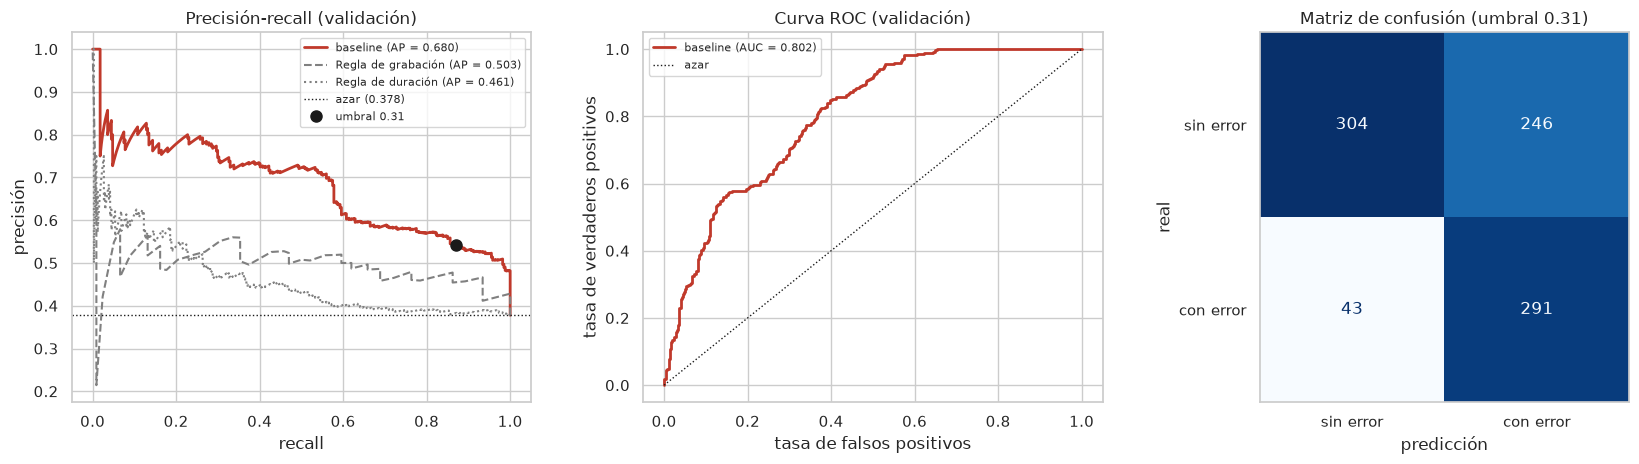

VP = 291, FN = 43, FP = 246, VN = 304


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1) Curva precisión-recall en validación
prec, rec, _ = precision_recall_curve(y_va, p_va)
axes[0].plot(rec, prec, color="#c0392b", lw=2, label=f"baseline (AP = {average_precision_score(y_va, p_va):.3f})")
for name, ls in [("Regla de grabación: video más corto", "--"), ("Regla de duración: paso más corto que su típico", ":")]:
    pr, rc, _ = precision_recall_curve(y_va, rules[name](X_va))
    axes[0].plot(rc, pr, ls=ls, color="gray", label=f"{name.split(':')[0]} (AP = {ref.loc[name, 'AUC-PR val']:.3f})")
axes[0].axhline(PREV_VA, color="k", ls=":", lw=1, label=f"azar ({PREV_VA:.3f})")
yhat = p_va >= THR
axes[0].plot(recall_score(y_va, yhat), precision_score(y_va, yhat), "ko", ms=8, label=f"umbral {THR:.2f}")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precisión"); axes[0].set_title("Precisión-recall (validación)")
axes[0].legend(fontsize=8)

# 2) ROC
fpr, tpr, _ = roc_curve(y_va, p_va)
axes[1].plot(fpr, tpr, color="#c0392b", lw=2, label=f"baseline (AUC = {roc_auc_score(y_va, p_va):.3f})")
axes[1].plot([0, 1], [0, 1], "k:", lw=1, label="azar")
axes[1].set_xlabel("tasa de falsos positivos"); axes[1].set_ylabel("tasa de verdaderos positivos")
axes[1].set_title("Curva ROC (validación)"); axes[1].legend(fontsize=8)

# 3) Matriz de confusión al umbral de operación
cm = confusion_matrix(y_va, yhat.astype(int))
ConfusionMatrixDisplay(cm, display_labels=["sin error", "con error"]).plot(ax=axes[2], colorbar=False, cmap="Blues")
axes[2].set_title(f"Matriz de confusión (umbral {THR:.2f})")
axes[2].grid(False); axes[2].set_xlabel("predicción"); axes[2].set_ylabel("real")
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"VP = {tp}, FN = {fn}, FP = {fp}, VN = {tn}")

**Interpretación.**

- **Precisión-recall.** La curva del baseline queda por encima de las reglas de grabación y de duración en todo el rango de recall, y muy por encima del azar (0.378). Con recall bajo la precisión está entre 0.8 y 1: los pasos con mayor puntaje casi siempre son errores. Por encima de un recall de 0.6 la precisión baja a ~0.55. El punto negro es el umbral de operación (0.31), elegido en entrenamiento: recall 87 % con precisión 54 %.
- **ROC (AUC 0.802).** El modelo ordena correctamente un par (paso con error, paso sin error) 8 de cada 10 veces.
- **Matriz de confusión.** De los 334 pasos con error de validación, el modelo marca 291 y deja pasar 43 (13 %). El costo son 246 falsos positivos: 537 marcas en total (61 % de los pasos). Con la prevalencia más alta de validación, marcar más de la mitad de los pasos es esperado; el umbral podrá subirse en el producto si el experto prefiere menos revisiones a cambio de algo de recall.

### 8.2 Calibración y análisis por grabación

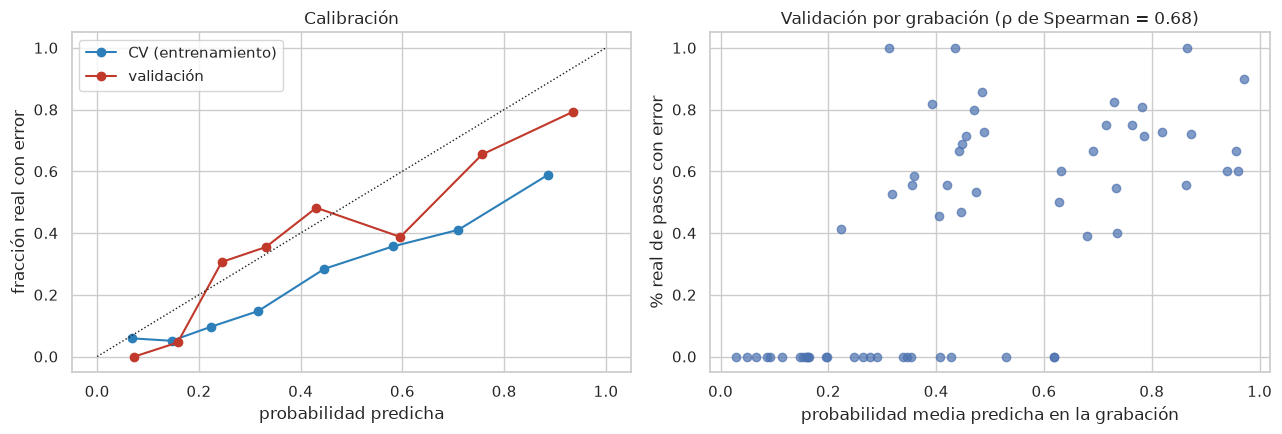

Grabaciones de validación con pasos de ambas clases: 33 de 62
AUC-PR medio DENTRO de la grabación: 0.741 vs prevalencia media en ellas: 0.639


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for y, p, lab, col in [(y_tr, p_oof, "CV (entrenamiento)", "#2c7fb8"), (y_va, p_va, "validación", "#c0392b")]:
    fr, mp = calibration_curve(y, p, n_bins=8, strategy="quantile")
    axes[0].plot(mp, fr, "o-", color=col, label=lab)
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set_xlabel("probabilidad predicha"); axes[0].set_ylabel("fracción real con error")
axes[0].set_title("Calibración"); axes[0].legend()

# Riesgo por grabación de validación: ¿el error se concentra en algunas grabaciones?
va_rec = parts["val"].loc[X_va.index, "recording_id"]
by_rec = pd.DataFrame({"real": y_va.groupby(va_rec).mean(), "predicho": pd.Series(p_va, index=X_va.index).groupby(va_rec).mean()})
axes[1].scatter(by_rec["predicho"], by_rec["real"], alpha=0.7)
axes[1].set_xlabel("probabilidad media predicha en la grabación"); axes[1].set_ylabel("% real de pasos con error")
axes[1].set_title(f"Validación por grabación (ρ de Spearman = {by_rec.corr('spearman').iloc[0, 1]:.2f})")
plt.tight_layout(); plt.show()

# AUC-PR dentro de cada grabación: ¿el modelo ordena los pasos de UN video, o solo distingue videos?
within = [average_precision_score(y_va[va_rec == r], p_va[(va_rec == r).to_numpy()])
          for r in va_rec.unique() if 0 < y_va[va_rec == r].mean() < 1]
prev_within = [y_va[va_rec == r].mean() for r in va_rec.unique() if 0 < y_va[va_rec == r].mean() < 1]
print(f"Grabaciones de validación con pasos de ambas clases: {len(within)} de {va_rec.nunique()}")
print(f"AUC-PR medio DENTRO de la grabación: {np.mean(within):.3f} vs prevalencia media en ellas: {np.mean(prev_within):.3f}")

**Interpretación.**

- **Calibración.** Las probabilidades están **sobreestimadas** en entrenamiento, consecuencia directa de `class_weight="balanced"` (el modelo "cree" que la mitad de los pasos tiene error). En validación la curva queda más cerca de la diagonal porque la prevalencia real es más alta. Para el ranking (AUC-PR) no importa, pero el semáforo del producto necesitará probabilidades calibradas (Platt o isotónica) en el modelo final.
- **Por grabación.** El promedio de probabilidad por video sigue al porcentaje real de errores del video (ρ de Spearman = 0.68): el modelo identifica razonablemente **qué grabaciones** tienen muchos errores. Los fallos más visibles son videos sin ningún error a los que el modelo asigna 0.4–0.6 de probabilidad media.
- **Dentro de la grabación.** En las 33 grabaciones de validación que tienen pasos de ambas clases, el AUC-PR medio dentro del video es 0.741 contra una prevalencia media de 0.639 (lift 1.16). Es decir, **ordenar los pasos dentro de un mismo video es mucho más difícil** que distinguir entre videos. Para el producto, que analiza un video a la vez, esta es la medida que más importa mejorar en los siguientes avances.

### 8.3 ¿El baseline alcanza el desempeño mínimo?

In [18]:
def check(name, ap, prev, rec, prec):
    return {"conjunto": name,
            "M1: AUC-PR ≥ 1.5 × prevalencia": f"{ap:.3f} ≥ {MIN_LIFT * prev:.3f} → {'sí' if ap >= MIN_LIFT * prev else 'no'}",
            "M2: supera la mejor regla": f"{ap:.3f} vs {ref.loc[BEST_RULE, 'AUC-PR ' + ('train' if 'CV' in name else 'val')]:.3f} → "
                                         f"{'sí' if ap > ref.loc[BEST_RULE, 'AUC-PR ' + ('train' if 'CV' in name else 'val')] else 'no'}",
            "M3: recall ≥ 70 % con precisión ≥ 1.4 × prevalencia": f"recall {rec:.1%}, precisión {prec:.3f} (mín. {MIN_PREC_LIFT * prev:.3f}) → "
                                                 f"{'sí' if rec >= MIN_RECALL and prec >= MIN_PREC_LIFT * prev else 'no'}"}

s_cv, s_va = scores(y_tr, p_oof, THR), scores(y_va, p_va, THR)
pd.DataFrame([check("CV agrupada (entrenamiento)", s_cv["AUC-PR"], PREV_TR, s_cv["Recall"], s_cv["Precisión"]),
              check("validación", s_va["AUC-PR"], PREV_VA, s_va["Recall"], s_va["Precisión"])]).set_index("conjunto").T

conjunto,CV agrupada (entrenamiento),validación
M1: AUC-PR ≥ 1.5 × prevalencia,0.514 ≥ 0.374 → sí,0.680 ≥ 0.567 → sí
M2: supera la mejor regla,0.514 vs 0.401 → sí,0.680 vs 0.503 → sí
M3: recall ≥ 70 % con precisión ≥ 1.4 × prevalencia,"recall 88.2%, precisión 0.385 (mín. 0.349) → sí","recall 87.1%, precisión 0.542 (mín. 0.529) → sí"


**Interpretación.** El baseline cumple los tres criterios en CV y en validación:

- **M1:** lift de 2.06 en CV y 1.80 en validación, por encima de 1.5.
- **M2:** supera a la mejor regla simple por +0.11 de AUC-PR en CV y +0.18 en validación.
- **M3:** encuentra 88 % (CV) y 87 % (validación) de los pasos con error, con una precisión 1.5 y 1.4 veces mayor que el azar. En validación el margen de M3 es estrecho (0.542 contra 0.529).

El problema es **viable**: un modelo lineal simple ya supera con claridad a las soluciones triviales, así que los datos sí contienen información para predecir el error. Al mismo tiempo, el nivel alcanzado (AUC-PR 0.55 en CV, ROC-AUC 0.80) deja margen amplio de mejora, y buena parte de la señal es de grabación y no de paso.

### 8.4 Tabla de referencia para los avances 4 y 5

In [19]:
# Tabla de referencia para los avances 4 y 5
summary = pd.DataFrame([
    {"modelo": "Azar (prevalencia)", "AUC-PR CV": PREV_TR, "AUC-PR val": PREV_VA},
    {"modelo": BEST_RULE, "AUC-PR CV": ref.loc[BEST_RULE, "AUC-PR train"], "AUC-PR val": ref.loc[BEST_RULE, "AUC-PR val"]},
    {"modelo": "Baseline: regresión logística (35 col.)", "AUC-PR CV": ap_folds.mean(), "AUC-PR val": s_va["AUC-PR"],
     "ROC-AUC val": s_va["ROC-AUC"], "F2 val": s_va["F2"], "Recall val": s_va["Recall"],
     "Precisión val": s_va["Precisión"], "entrenamiento (ms)": 1000 * fit_time},
    {"modelo": "Baseline sin rec_duration (34 col.)", "AUC-PR CV": var_tab.loc["B. A sin rec_duration (34)", "AUC-PR CV"],
     "AUC-PR val": var_tab.loc["B. A sin rec_duration (34)", "AUC-PR val"]},
]).set_index("modelo")
summary

,AUC-PR CV,AUC-PR val,ROC-AUC val,F2 val,Recall val,Precisión val,entrenamiento (ms)
modelo,,,,,,,
Azar (prevalencia),0.249,0.378,NaN,NaN,NaN,NaN,NaN
Regla de grabación: video más corto,0.401,0.503,NaN,NaN,NaN,NaN,NaN
Baseline: regresión logística (35 col.),0.551,0.680,0.802,0.777,0.871,0.542,15.921
Baseline sin rec_duration (34 col.),0.474,0.628,NaN,NaN,NaN,NaN,NaN


## 9. Conclusiones

**Respuestas a las preguntas guía**

1. **Algoritmo.** Regresión logística con regularización L2 (C = 1) y pesos balanceados. Es adecuada para datos estructurados, pocos y ya estandarizados; da probabilidades y coeficientes explicables, y entrena en milisegundos en CPU, como pide un producto local de costo cero. Un árbol igual de simple rinde mucho menos (0.337 contra 0.551).
2. **Importancia de características.** Sí se puede determinar, y los cuatro métodos coinciden. Lo más importante es la duración del video (`rec_duration`), seguida del número de pasos de la grabación, la posición del paso y el orden de la receta (`order_violation` casi quintuplica los momios de error). `step_id_freq`, `repeat_idx` y `n_pred_absent` no aportan. `duration` sí aporta junto con `dur_ratio_step` (+0.017 en los 5 pliegues) y se agrega para el avance 4.
3. **Sub/sobreajuste.** No hay sobreajuste: la brecha entre entrenamiento y CV es de 0.05 a 0.07 y no crece al quitar regularización. Hay **subajuste ligero**: las curvas de aprendizaje convergen cerca de 0.55–0.60 y más datos ya no ayudan. Hace falta un modelo con más capacidad, no más datos.
4. **Métrica.** AUC-PR como métrica principal (desbalance de 25 %, ranking para revisión humana, sin umbral fijo), con F2, recall y precisión al umbral de operación. La exactitud se descarta: 75 % sin detectar ningún error.
5. **Desempeño mínimo.** No hay histórico. Se fijó contra el azar y reglas simples, más un criterio de negocio (encontrar 7 de cada 10 errores revisando como mucho la mitad de los pasos). El baseline los cumple: AUC-PR 0.551 en CV (lift 2.2 por pliegue) y 0.680 en validación, recall de 87 % con precisión de 54 %.

**Riesgos y siguientes pasos**

- **Dependencia de la grabación.** Sin `rec_duration` el baseline baja a 0.474 (CV) y 0.628 (validación), y dentro de un mismo video el lift es de solo 1.16. En el avance 4 se reportarán los modelos con y sin las variables de grabación; la versión sin ellas es la que mejor representa el caso de uso en planta.
- **Prevalencia distinta entre particiones** (24.9 % contra 37.8 %). Siempre se compararán lifts además de valores absolutos.
- **Calibración.** Las probabilidades están sobreestimadas por los pesos balanceados; el modelo final deberá calibrarse antes de alimentar el semáforo.
- **Avance 4.** Al menos 6 modelos individuales sobre las 36 columnas (las 35 actuales + `duration`), con la misma validación cruzada agrupada, la misma métrica y esta tabla como referencia mínima.

## Referencias

- Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.
- Peddi, R., et al. (2024). CaptainCook4D: A dataset for understanding errors in procedural activities. *NeurIPS 2024 Datasets and Benchmarks Track.* https://arxiv.org/abs/2312.14556
- Saito, T., y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432.
- Studer, S., Bui, T. B., Drescher, C., Hanuschkin, A., Winkler, L., Peters, S., y Müller, K.-R. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction, 3*(2), 392–413.
- Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., y Plöd, M. (2023). *CRISP-ML(Q). The ML lifecycle process.* MLOps, INNOQ. https://ml-ops.org/content/crisp-ml